# Spectral Clustering
### TMA4205 Numerical Linear Algebra

This project looks at implementation and testing of eigenvalue/eigenvector algorithms, in particular for large, symmetric and sparse matrices. For this we will use spectral clustering, and we thus want to investigate how eigenvectors can be used to improve clustering.

In [1]:
# Imports
import numpy as np
import matplotlib.pyplot as plt
import scipy.sparse as sp
import scipy.linalg as la
from scipy.sparse.csgraph import connected_components
from sklearn.neighbors import kneighbors_graph
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score
from scipy.sparse.linalg import eigsh
import time
import os

os.makedirs("figures", exist_ok=True)   # SVG files of the plots, for the report

In [2]:
# Hand-out code

point_size = 10

def make_data(n=100, sigma = 0.5, pl=False):
    '''
    Make four clusters: noisy data points around 4 centres.
    
    Parameters:
    n: number of points in each cluster (default 100)
    sigma: Level of noise (default 0.5)
    pl: Make a plot or not  (default False)

    Return:
    X: the data points, np.array of shape (4*n,2)
    '''
    centers = np.array([[0, 0],[1, 5],[4, 0],[5, 5]])
    X = np.vstack([center + sigma * np.random.randn(n, 2) for center in centers])
    if pl:
        plt.clf()
        plt.scatter(X[:, 0], X[:, 1], s=point_size)
        plt.axis('equal')
        plt.show()
    return X


def make_moons(n = 150, sigma = 0.12, pl = False):
    '''
    Make four half circles.

    Parameters:
    n: Number of data points in each half circle (default 150)
    sigma : Noise level, or the spread of data (default 0.12)
    pl:  Make a plot or not  (default False)

    Return:
    X: The data points, np.array of shape (4*n,2)
    '''
    X = []
    labels = []
    # Four moons, separated spatially
    centers = [(0, 0), (1, 0), (-2.5, -2), (-1, -2)]
    for j, (cx, cy) in enumerate(centers):
        t = np.linspace(0, np.pi, n)
        x = 1.5 * np.cos(t)
        y = 1.5 * np.sin(t)
        # Put the four moons in different orientations
        if j == 1:
            y = -y
        elif j == 2:
            x = -x
        elif j == 3:
            x = -x
            y = -y
        x += cx + sigma*np.random.randn(n)
        y += cy + sigma*np.random.randn(n)
        X.append(np.column_stack((x, y)))
        labels.extend([j]*n)
    X = np.vstack(X)
    labels = np.array(labels)

    if pl:
        plt.clf()
        plt.scatter(X[:,0], X[:,1], c=labels, s=point_size)
        plt.axis("equal")
        plt.show()
    return X


# Part 1: Understanding spectral clustering

In this task we construct a symmetric $k$-nearest-neighbour graph and assign weights to its edges using the Gaussian similarity function
$$
s(x_i, x_j) = \exp \left( \frac{- ||x_i - x_j||_2^2}{2 \sigma^2} \right)
$$
where $\sigma$ controls the width of the neighbourhood.

The unnormalized graph Laplacian matrix is defined as 
$$ L = D - W$$

Below we have implemented an algorithm for spectral clustering, using standard Python functions.

In [3]:
def build_laplacian(X, k=10, sigma=1):
    '''
    Unnormalized graph Laplacian of the symmetric k-nearest-neighbour graph with Gaussian weights.

    Parameters:
        X: The data points, np.array of shape (N,2)
        k: The number of nearest neighbors to use in the graph (default 10)
        sigma: The value of sigma to use in the Gaussian weights (default 1)

    Return:
        L: The Laplacian matrix, scipy sparse matrix of shape (N,N)
    '''

    # Make the k-nearest neighbor graph
    S = kneighbors_graph(X, k, mode='distance', include_self=False)
    S = S.maximum(S.T).tocsr() # Make the graph symmetric

    # Compute the Gaussian weights on the existing edges only (keeps W sparse)
    W = S.copy()
    W.data = np.exp(-W.data**2 / (2 * sigma**2))

    # Compute the degree matrix D and the Laplacian L
    N = W.shape[0]
    D = sp.diags(np.asarray(W.sum(axis=1)).ravel())
    L = (D - W).tocsr()

    return L


def spectral_clustering(X, k=10, K=4, sigma=1):
    '''
    Spectral clustering algorithm.

    Parameters:
        X: The data points, np.array of shape (N,2)
        k: The number of nearest neighbors to use in the graph (default 10)
        K: The number of clusters to find (default 4)
        sigma: The value of sigma to use in the Gaussian weights (default 1)

    Return:
        C: The cluster labels, np.array of shape (N,)
        L: The Laplacian matrix, scipy sparse matrix of shape (N,N)
        lambdas: The eigenvalues of the Laplacian, np.array of shape (N,)
        V: The eigenvectors of the Laplacian, np.array of shape (N,N)
    '''

    # Make the graph Laplacian
    L = build_laplacian(X, k, sigma)

    # Compute the eigenvalues and eigenvectors of the Laplacian
    lambdas, V = la.eigh(L.toarray())
    U = V[:, :K]

    # Perform k-means clustering on the rows of U
    C = KMeans(n_clusters=K, n_init=10, random_state=0).fit(U).labels_

    return C, L, lambdas, V


In [4]:
colors = ["#3FC38B", "#FF8C42", "#4DA3E0", "#F7B731","#F26B6B",
              "#9B6BD6",  "#E85D9E", "#1B5E3F",]

def plot_clusters(X, C, title="Spectral clustering", filename=None):
    '''
    Scatter plot of 2D data points coloured by cluster label.

    Parameters:
        X: The data points, np.array of shape (N,2)
        C: The cluster labels, np.array of shape (N,)
        title: The plot title
        filename: Optional file name; if given, the plot is saved as figures/<filename>.svg
    '''
    palette = np.array(colors)
    fig, ax = plt.subplots(figsize=(9, 7))

    for c in np.unique(C):
        mask = C == c
        ax.scatter(X[mask, 0], X[mask, 1], s=40, color=palette[c], alpha=0.85,
                   edgecolor="white", linewidth=0.5, label=f"Cluster {c + 1}")

    ax.set_title(title, fontsize=16, pad=12)
    ax.set_xlabel("$x_1$")
    ax.set_ylabel("$x_2$")
    ax.set_aspect("equal", adjustable="datalim")   # keeps the geometry undistorted
    ax.grid(alpha=0.25)
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(frameon=False, loc="best", markerscale=1.2)
    fig.tight_layout()
    if filename is not None:
        fig.savefig(f"figures/{filename}.svg", bbox_inches="tight")
    plt.show()

### `make_data()` dataset
Before plotting the clustering results, we are interested in understanding the properties of the Laplacian matrix L. In particular, we want to look at if the following properties are satisfied:

**Proposition 1 (Properties of $L$).** *The matrix $L$ satisfies the following properties:*

1. *For every vector $f \in \mathbb{R}^n$ we have*
$$
f' L f = \frac{1}{2} \sum_{i,j=1}^{n} w_{ij} (f_i - f_j)^2.
$$
2. *$L$ is symmetric and positive semi-definite.*
3. *The smallest eigenvalue of $L$ is $0$, the corresponding eigenvector is the constant one vector $\mathbb{1}$.*
4. *$L$ has $n$ non-negative, real-valued eigenvalues $0 = \lambda_1 \leq \lambda_2 \leq \dots \leq \lambda_n$.*

In [5]:
# Properties of the Laplacian for the Gaussian dataset
np.random.seed(0)                                            
X = make_data()
C_gauss, L, lambdas, V = spectral_clustering(X, k=10, K=4, sigma=1)  

W = sp.diags(L.diagonal()) - L                                # W = D - L
ev = la.eigvals(L.toarray())                                  # general solver
lam = np.sort(ev.real)                                        # sorted spectrum: lam[0] = lambda_1
tol = 1e-10 * lam[-1]                                         # "numerically zero" threshold, relative to lambda_max

f = np.random.default_rng(0).standard_normal(L.shape[0])      # random test vector
Wc = W.tocoo()                                                # edge list (i, j, w_ij) for summing over edges
lhs = f @ (L @ f)                                             # item 1: matrix side, f'Lf
rhs = 0.5 * np.sum(Wc.data * (f[Wc.row] - f[Wc.col])**2)     # item 1: edge side, 1/2 sum w_ij (f_i - f_j)^2

print(f"1. f'Lf = {lhs:.10e},  1/2 sum w_ij (f_i - f_j)^2 = {rhs:.10e}")
print(f"2. max|L - L^T| = {abs(L - L.T).max():.1e},  smallest eigenvalue = {lam[0]:.1e}")
print(f"3. max|L 1| = {np.abs(L @ np.ones(L.shape[0])).max():.1e}")
print(f"4. max|Im(lambda)| = {np.abs(ev.imag).max():.1e},  6 smallest eigenvalues = {lam[:6]}")


1. f'Lf = 4.7454411120e+03,  1/2 sum w_ij (f_i - f_j)^2 = 4.7454411120e+03
2. max|L - L^T| = 0.0e+00,  smallest eigenvalue = -1.3e-15
3. max|L 1| = 5.3e-15
4. max|Im(lambda)| = 0.0e+00,  6 smallest eigenvalues = [-1.33226763e-15  2.22044605e-16  5.55111512e-16  1.77635684e-15
  6.19366152e-01  6.70144618e-01]


For `make_data()` ($N = 4n = 400$, $k = 10$, $\sigma = 1$), all checks pass up to floating-point rounding ($\varepsilon \approx 2.2 \times 10^{-16}$):

1. **Quadratic form:** both sides agree to 11 digits, $f^\top L f = \tfrac{1}{2}\sum_{i,j} w_{ij}(f_i - f_j)^2 \approx 4745.44$.
2. **Symmetric and PSD:** $L - L^\top = 0$ exactly, and $\lambda_1 = -1.3 \times 10^{-15}$ is zero up to rounding.
3. **Eigenvalue 0 with eigenvector $\mathbb{1}$:** $\max|L\mathbb{1}| \approx 5 \times 10^{-15}$, so $L\mathbb{1} = 0$.
4. **Real, non-negative eigenvalues:** imaginary parts are exactly zero, and none are negative beyond rounding.

Item 3 shows that $0$ is always an eigenvalue of $L$. Proposition 2 goes further and relates its multiplicity to the connectivity of the graph:

**Proposition 2 (Number of connected components and the spectrum of $L$).** *Let $G$ be an undirected graph with non-negative weights. Then the multiplicity $m$ of the eigenvalue $0$ of $L$ equals the number of connected components $A_1, \dots, A_m$ in the graph. The eigenspace of eigenvalue $0$ is spanned by the indicator vectors $\mathbb{1}_{A_1}, \dots, \mathbb{1}_{A_m}$ of those components.*

In [6]:
# Prop. 2: components counted from W, independent of eigenvalues
n_comp, _ = connected_components(W, directed=False)
print(f"zero eigenvalues = {np.sum(np.abs(lam) < tol)},  connected components = {n_comp}")

zero eigenvalues = 4,  connected components = 4


The six smallest eigenvalues are $\lambda_1, \dots, \lambda_6 \approx -1.3 \cdot 10^{-15},\ 2.2 \cdot 10^{-16},\ 5.6 \cdot 10^{-16},\ 1.8 \cdot 10^{-15},\ 0.62,\ 0.67$. The clear gap after $\lambda_4$ gives exactly four zero eigenvalues, and `connected_components` confirms four components, one per cluster. This is the ideal case: the $k$-NN graph separates the clusters completely, $u_1, \dots, u_4$ span the cluster indicators, and $K$-means on the rows of $U$ trivially recovers the clusters (von Luxburg §7). The eigengap after $\lambda_4$ also correctly suggests $K = 4$.

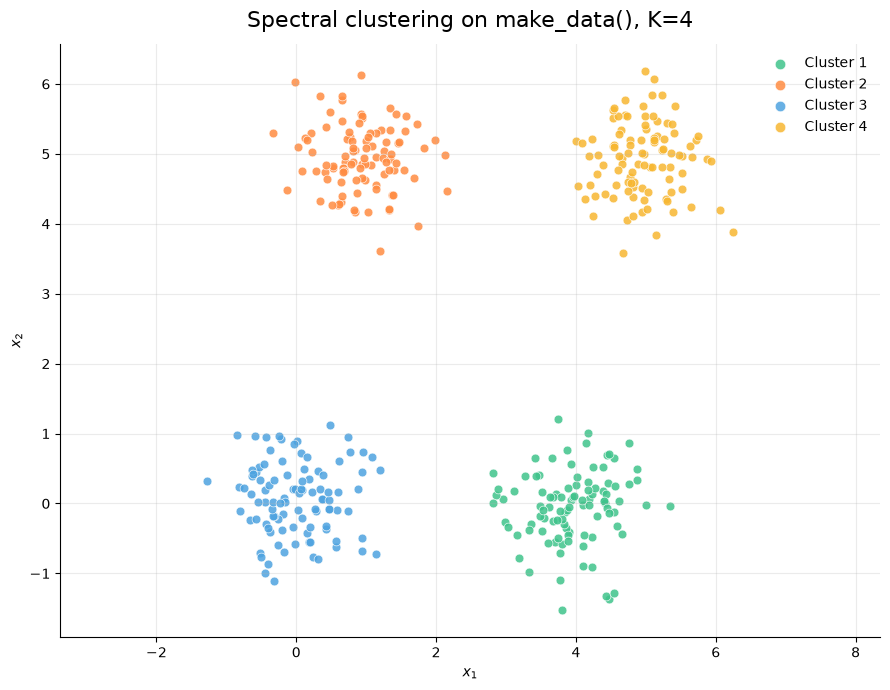

In [7]:
plot_clusters(X, C_gauss, title="Spectral clustering on make_data(), K=4", filename="Gaussian")

The plot shows that all four clusters are recovered correctly.


### `make_moons()` dataset
Now we will move on to look at the `make_moons()` dataset.

In [8]:
# Check the properties of the Laplacian matrix for the moons dataset
np.random.seed(0)                                            
Y = make_moons()
C_moons, L_moons, lambdas_moons, V_moons = spectral_clustering(Y, k=10, K=4, sigma=1)  

W_moons = sp.diags(L_moons.diagonal()) - L_moons                                                # W = D - L
ev_moons = la.eigvals(L_moons.toarray())                                                        # general solver
lam_moons = np.sort(ev_moons.real)                                                              # sorted spectrum: lam[0] = lambda_1
tol_moons = 1e-10 * lam_moons[-1]                                                               # "numerically zero" threshold, relative to lambda_max

f_moons = np.random.default_rng(0).standard_normal(L_moons.shape[0])                            # random test vector
Wc_moons = W_moons.tocoo()                                                                      # edge list (i, j, w_ij) for summing over edges
lhs_moons = f_moons @ (L_moons @ f_moons)                                                       # item 1: matrix side, f'Lf
rhs_moons = 0.5 * np.sum(Wc_moons.data * (f_moons[Wc_moons.row] - f_moons[Wc_moons.col])**2)    # item 1: edge side, 1/2 sum w_ij (f_i - f_j)^2
n_comp_moons, _ = connected_components(W_moons, directed=False)                                 # Prop. 2: components counted from W, independent of eigenvalues

print(f"1. f'Lf = {lhs_moons:.10e},  1/2 sum w_ij (f_i - f_j)^2 = {rhs_moons:.10e}")
print(f"2. max|L - L^T| = {abs(L_moons - L_moons.T).max():.1e},  smallest eigenvalue = {lam_moons[0]:.1e}")
print(f"3. max|L 1| = {np.abs(L_moons @ np.ones(L_moons.shape[0])).max():.1e}")
print(f"4. max|Im(lambda)| = {np.abs(ev_moons.imag).max():.1e},  6 smallest eigenvalues = {lam_moons[:6]}")
print(f"zero eigenvalues = {np.sum(np.abs(lam_moons) < tol_moons)},  connected components = {n_comp_moons}")


1. f'Lf = 7.0681956872e+03,  1/2 sum w_ij (f_i - f_j)^2 = 7.0681956872e+03
2. max|L - L^T| = 0.0e+00,  smallest eigenvalue = -1.5e-15
3. max|L 1| = 5.3e-15
4. max|Im(lambda)| = 0.0e+00,  6 smallest eigenvalues = [-1.52261614e-15 -1.09634524e-15  1.04083409e-17  1.29565798e-02
  3.45712613e-02  3.51343227e-02]
zero eigenvalues = 3,  connected components = 3


For `make_moons()` ($k = 10$, $\sigma = 1$), all checks of Proposition 1 again pass up to rounding: both sides of the quadratic form agree to 11 digits ($\approx 7068.20$), $L - L^\top = 0$ exactly, $\max|L\mathbb{1}| \approx 5 \times 10^{-15}$, and the eigenvalues are real with $\lambda_1 = -1.5 \times 10^{-15}$ zero up to rounding.

For Proposition 2, the six smallest eigenvalues are $\lambda_1, \dots, \lambda_6 \approx -1.5 \cdot 10^{-15},\ -1.1 \cdot 10^{-15},\ 1.0 \cdot 10^{-17},\ 0.013,\ 0.035,\ 0.035$. Three are numerically zero, matching the three connected components. Unlike the Gaussian case, this is fewer than $K = 4$: the right and bottom moons are connected by edges in the $k$-NN graph, so the graph is not perfectly separated. This shows up as $\lambda_4 \approx 0.013$, small but not zero. This is the nearly ideal case of the perturbation argument (von Luxburg §7): $u_4$ has to split the merged component, but since $\lambda_4$ is small and the gaps $\lambda_4 - \lambda_3 \approx 0.013$ and $\lambda_5 - \lambda_4 \approx 0.022$ are both small, the split is less reliable than for the Gaussian data (see below).

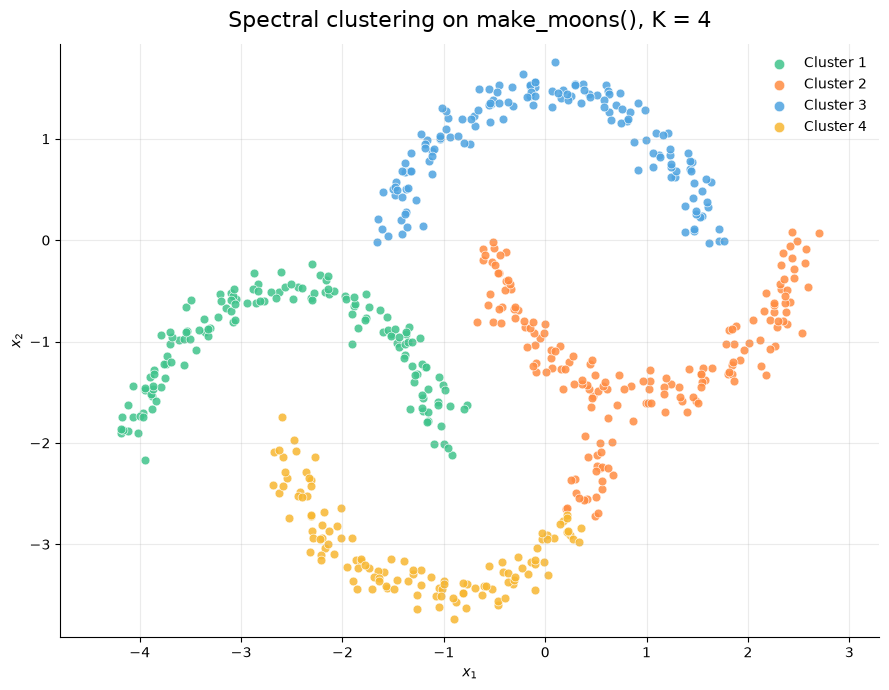

In [9]:
plot_clusters(Y, C_moons, title="Spectral clustering on make_moons(), K = 4", filename="moons_K4")

With $\sigma = 1$ and $K = 4$, the top and left moons are recovered exactly. The right moon and the bottom moon form one connected component, and the cut through it is misplaced: the right end of the bottom moon is assigned to the right moon.

sigma = 0.237


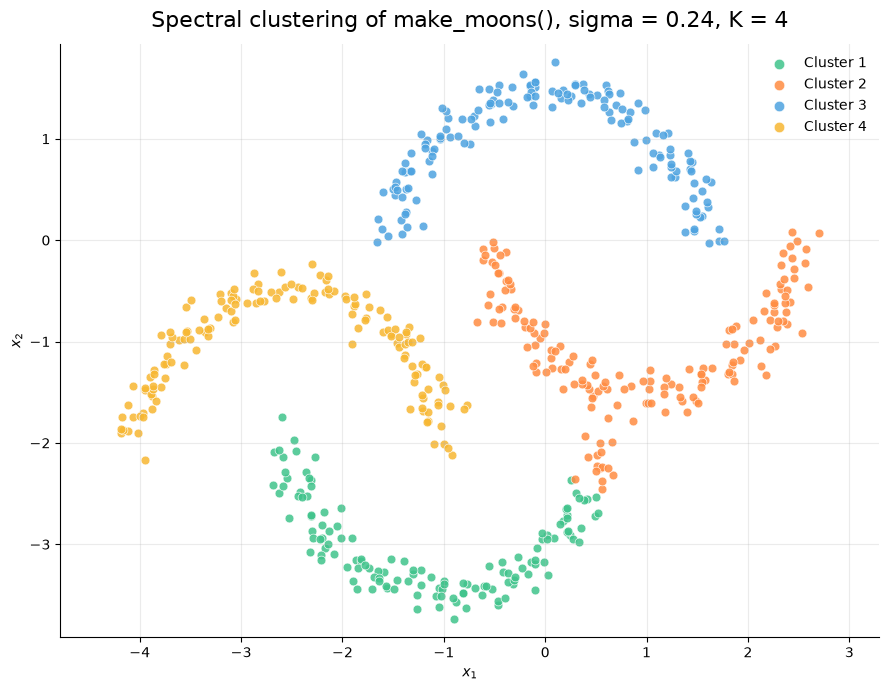

In [10]:
# Rule of thumb (von Luxburg §8.1): sigma = mean distance to the k-th nearest neighbour
sigma_moons = kneighbors_graph(Y, 10, mode='distance').max(axis=1).toarray().mean()
print(f"sigma = {sigma_moons:.3f}")

C_moons_s, L_moons_s, lambdas_moons_s, V_moons_s = spectral_clustering(Y, k=10, K=4, sigma=sigma_moons)
plot_clusters(Y, C_moons_s, f"Spectral clustering of make_moons(), sigma = {sigma_moons:.2f}, K = 4", filename="moons_sigma")

With $\sigma = \bar d_k = 0.237$, the result is essentially unchanged (cluster colours are permuted, since the labelling is arbitrary). In a $k$-NN graph, $\sigma$ only reweights existing edges and cannot remove the edges between the two touching moons, so the misplaced cut remains.

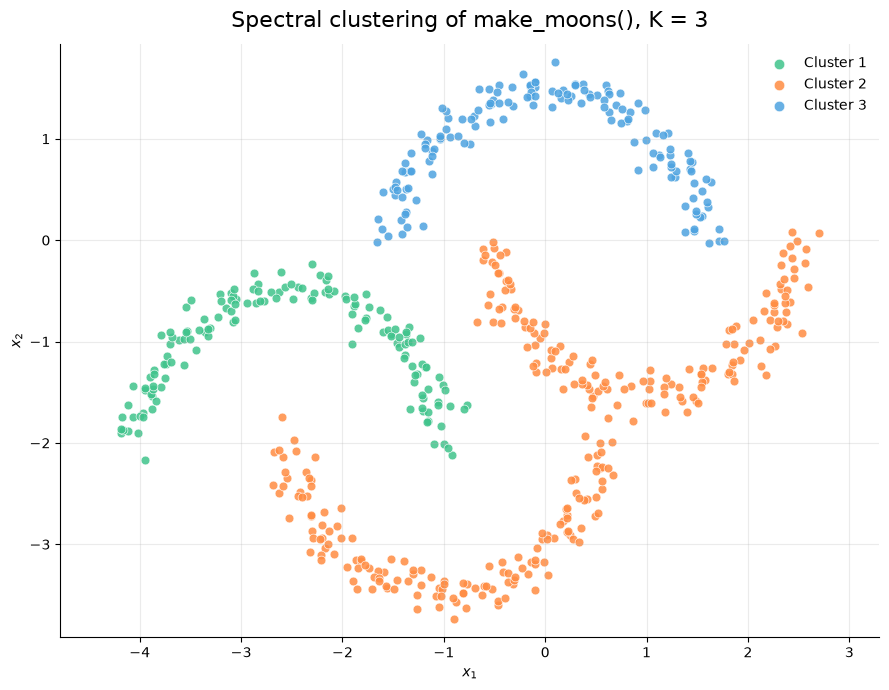

In [11]:
C_moons_3, _, _, _ = spectral_clustering(Y, k=10, K=3, sigma=1)
plot_clusters(Y, C_moons_3, f"Spectral clustering of make_moons(), K = 3", filename="moons_K3")

With $K = 3$, equal to the number of connected components, spectral clustering returns exactly the components: the right and bottom moons are merged into one cluster (von Luxburg §8.1).

**Choice of $\sigma$.** Following von Luxburg (§8.1), we compare $\sigma=1$ to $\sigma$ on the order of the mean distance to the $k$-th nearest neighbour, $\sigma = \bar d_k \approx 0.24$ for the moons ($k = 10$). Both choices give practically the same clustering, since $\sigma$ does not change the connectivity of the $k$-NN graph. The clustering here is determined by the graph connectivity, thus we keep  $\sigma = 1$ as the main choice.

**Choice of $K$.** The data consists of four moons by construction, so $K = 4$. The eigengap heuristic (von Luxburg §8.3) is ambiguous here: $\lambda_1, \lambda_2, \lambda_3 \approx 0$ followed by $\lambda_4 \approx 1.3\cdot 10^{-2}$ suggests $K = 3$, while the gap $\lambda_5 - \lambda_4 \approx 2.2\cdot 10^{-2}$ supports $K = 4$. For the Gaussian clusters, the heuristic clearly gives $K = 4$ ($\lambda_1, \dots, \lambda_4 \approx 0$, $\lambda_5 \approx 0.62$).

In [12]:
for k in [4, 5, 6, 7, 8, 10]:
    S = kneighbors_graph(Y, k, mode='distance', include_self=False)
    print(f"k = {k:2d}: components = {connected_components(S.maximum(S.T), directed=False)[0]}")

k =  4: components = 7
k =  5: components = 3
k =  6: components = 3
k =  7: components = 3
k =  8: components = 3
k = 10: components = 3


For $k \geq 5$ the graph always has three components, while $k = 4$ already breaks the moons into seven pieces. None of the tested values of $k$ separates the right and bottom moons without fragmenting the others, so with the unnormalized Laplacian and a symmetric $k$-NN graph these two moons cannot be fully separated on this sample.

# Part 2: Implement and test eigenvalue/eigenvector solvers

In this part we will implement and investigate three different eigenvalue algorithms:
* Power iteration
* QR iteration
* Lanczos iteration

## Power Iteration
Power iteration in itself can only find the eigenvector corresponding to the eigenvalue of the largest absolute value. In our project, we are interested in the smallest eigenvalues, and therefore need to adapt the algorithm accordingly. We therefore apply power iteration to the shifted matrix
$$B = cI - L, \quad \lambda_i(B) = c - \lambda_i(L)$$
with $c = 2d_{\max} \geq \lambda_{\max}(L)$ (Gershgorin).

B has the same eigenvectors as L, but the order is reversed. The smallest eigenvalue of L becomes the dominant one of B, and we can recover it as $\lambda(L) = c - \lambda(B)$.

In [13]:
def power_iteration(L, tol=1e-10, maxiter=1000, seed=0, c=None, found=None, callback=None):
    """
    Power iteration algorithm to compute the dominant eigenvalue and eigenvector of the graph Laplacian L.

    Parameters:
        L: The input matrix (sparse or dense)
        tol: The tolerance for convergence
        maxiter: The maximum number of iterations
        seed: The seed for the random number generator
        c: The shift. If None, power iteration is applied to L. If given, it is applied to c*I - L (requires c >= lambda_max(L)), which gives the smallest eigenpair of L.
        found: Optional list of previously computed eigenvectors (orthonormal). If given, the iterates are kept
               orthogonal to these vectors (deflation), so the method converges to the next eigenpair.
        callback: Optional function callback(lambda, v), called in every iteration with the current eigenvalue
                  estimate of L (shifted back if c is given) and the iterate v^(k). Used for the error plots.

    Returns:
        lambda^(k): The dominant eigenvalue after k iterations
        v^(k): The dominant eigenvector after k iterations
        k: The number of iterations performed
        converged: A boolean indicating whether the algorithm converged within the specified tolerance
        history: A list of residuals at each iteration
    """

    def apply(x):
        # Matrix-vector multiplication with L, or with the shifted matrix c*I - L
        return L @ x if c is None else c * x - L @ x

    # Deflation: matrix X with the found eigenvectors as columns
    X = np.column_stack(found) if found else None

    def deflate(x):
        # Deflation: remove the components of x along the found eigenvectors, x - X X^T x
        return x if X is None else x - X @ (X.T @ x)

    # Initialize a random vector v^(0), orthogonal to the found eigenvectors
    rng = np.random.default_rng(seed)
    v = deflate(rng.standard_normal(L.shape[0]))
    v = v / la.norm(v) # Normalize the vector

    w = deflate(apply(v))   # Initial matrix-vector multiplication: w = A v^(0), deflated
    converged = False  # Flag to check for convergence
    history = []

    for k in range(1, maxiter+1):
        v = w / la.norm(w)  # Normalize the vector, v^(k) = A v^(k-1) / ||A v^(k-1)||

        # Deflation in every iteration: rounding errors would otherwise reintroduce the found directions
        w = deflate(apply(v))  # Matrix-vector multiplication, A v^(k), reused in the next iteration

        lambda_ = v @ w  # Rayleigh quotient to estimate the eigenvalue, lambda^(k) = (v^(k))^T A v^(k)
        res = la.norm(w - lambda_ * v)  # Compute the residual of the pair (lambda^(k), v^(k))
        history.append(res)  # Store the residual for analysis
        if callback is not None:
            callback(lambda_ if c is None else c - lambda_, v)
        if res < tol: # Check for convergence
            converged = True
            break

    if c is not None:
        lambda_ = c - lambda_  # Shift back: eigenvalue of L = c - eigenvalue of c*I - L

    return lambda_, v, k, converged, history


In [14]:
# Simple check of power_iteration on a small matrix with known eigenpairs
A = np.diag([1.0, 2.0, 5.0])    # eigenvalues 1, 2, 5; eigenvectors e_1, e_2, e_3

# Largest eigenpair: expect lambda = 5 and v = (0, 0, ±1)
lam, v, n_iter, conv, hist = power_iteration(A)
print("Largest: ", lam, v, n_iter, conv)

# Smallest eigenpair with shift c = 6 >= 5: expect lambda = 1 and v = (±1, 0, 0)
lam, v, n_iter, conv, hist = power_iteration(A, c=6)
print("Smallest:", lam, v, n_iter, conv)

Largest:  5.0 [ 6.58753427e-19 -2.32247959e-11  1.00000000e+00] 25 True
Smallest: 1.0 [ 1.00000000e+00 -8.76673288e-11  1.03310997e-72] 104 True


The method finds the correct eigenpairs, and the shift turns the smallest eigenvalue into the dominant one, as intended. The iteration counts agree with the predicted rates $r = |\lambda_2/\lambda_1|$, i.e. $2/5$ for $A$ and $4/5$ for $6I - A$.

In [15]:
# Smallest eigenpair of L with shifted power iteration
d = L.diagonal()    # degrees d_i (diagonal of L)
c = 2 * d.max() # Gershgorin: lambda_max(L) <= 2 max_i d_i, so c >= lambda_max

lam, v, n_iter, conv, hist = power_iteration(L, maxiter=10000, c=c)

# Reference solution: lambdas, V from spectral_clustering above
tol0 = 1e-10 * lambdas[-1]  # threshold for "numerically equal"
m = np.sum(lambdas - lambdas[0] < tol0) # multiplicity of lambda_1
Q = V[:, :m]    # orthonormal basis of the eigenspace of lambda_1

print(f"c = {c:.3f},  converged = {conv},  iterations = {n_iter}")
print(f"Eigenvalue: {lam}")
print(f"Eigenvalue error |lam - lambda_1| = {abs(lam - lambdas[0]):.2e}")
print(f"Multiplicity of lambda_1: m = {m}")
print(f"Distance from v to span(u_1..u_m) = {la.norm(v - Q @ (Q.T @ v)):.2e}")
print(f"Overlap |v^T u_1| = {abs(v @ V[:, 0]):.2f}")

c = 34.861,  converged = True,  iterations = 1231
Eigenvalue: 7.105427357601002e-15
Eigenvalue error |lam - lambda_1| = 7.11e-15
Multiplicity of lambda_1: m = 4
Distance from v to span(u_1..u_m) = 1.60e-10
Overlap |v^T u_1| = 0.29


The eigenvalue is correct to rounding level. The distance $1.6 \cdot 10^{-10}$ shows that $v$ lies in the eigenspace of $\lambda = 0$, so $v$ is a correct eigenvector (the distance is as small as the tolerance allows, $\approx 10^{-10}/(\lambda_5 - \lambda_1)$). However, this eigenspace has dimension $m = 4$, and the overlap $0.29$ shows that $v$ is not $u_1$ but some combination of $u_1, \dots, u_4$, determined by the starting vector. One run therefore only gives one direction in a four-dimensional eigenspace, while clustering needs a basis of the whole eigenspace. We obtain this with deflation.

In [16]:
# K smallest eigenpairs of L with shifted power iteration and deflation
n_pairs = 6
found = []
lams = []
for j in range(n_pairs):
    lam, v, n_iter, conv, hist = power_iteration(L, maxiter=100000, c=c, found=found)
    found.append(v)
    lams.append(lam)
    print(f"Eigenpair {j+1}: lambda = {lam:.2e}, iterations = {n_iter}, converged = {conv}")

U = np.column_stack(found)   # N x n_pairs matrix with the computed eigenvectors as columns

Eigenpair 1: lambda = 7.11e-15, iterations = 1231, converged = True
Eigenpair 2: lambda = 7.11e-15, iterations = 3158, converged = True
Eigenpair 3: lambda = 2.13e-14, iterations = 3291, converged = True
Eigenpair 4: lambda = -2.13e-14, iterations = 3257, converged = True
Eigenpair 5: lambda = 6.19e-01, iterations = 13705, converged = True
Eigenpair 6: lambda = 6.70e-01, iterations = 25181, converged = True


With deflation, each run is kept orthogonal to the vectors already found, so the runs converge to successive eigenpairs: runs 1–4 give four eigenvectors for $\lambda = 0$, and runs 5–6 continue to $\lambda_5$ and $\lambda_6$. Runs 2–4 are slower than run 1 because every run uses the same starting vector: run 1 converged to its projection onto the eigenspace, so deflating $v_1$ removes almost all of its component there, and this has to grow back from rounding level. Runs 5–6 are slow because $\lambda_5$ and $\lambda_6$ are close to the next eigenvalues. Below we therefore use a different seed for each run.

In [17]:
def theoretical_rate(lambdas, j, c, tol0):
    '''
    Theoretical convergence rate of shifted power iteration with deflation for eigenpair j,
    r_j = (c - lambda_next) / (c - lambda_j), where lambda_next is the next distinct eigenvalue.

    Parameters:
        lambdas: Eigenvalues of L in ascending order, np.array of shape (N,)
        j: Index of the eigenpair
        c: The shift
        tol0: Threshold for "numerically equal" eigenvalues

    Return:
        r: The theoretical rate
    '''
    i_next = np.argmax(lambdas > lambdas[j] + tol0)
    return (c - lambdas[i_next]) / (c - lambdas[j])

In [18]:
def deflation_convergence(L, lambdas, n_pairs, name, ax, tol=1e-10, maxiter=50000):
    '''
    Compute the n_pairs smallest eigenpairs of L with shifted power iteration and deflation, and plot the
    residual history of each run against the theoretical rate r_j = (c - lambda_next) / (c - lambda_j).

    Parameters:
        L: The graph Laplacian, scipy sparse matrix of shape (N,N)
        lambdas: Reference eigenvalues of L in ascending order, np.array of shape (N,)
        n_pairs: The number of eigenpairs to compute
        name: Name of the data set, used in the title and printout
        ax: Matplotlib axes to plot in
        tol: Tolerance for power iteration
        maxiter: The maximum number of iterations per run

    Return:
        U: The computed eigenvectors as columns, np.array of shape (N,n_pairs)
        lams: The computed eigenvalues, np.array of shape (n_pairs,)
    '''

    c = 2 * L.diagonal().max()
    tol0 = 1e-10 * lambdas[-1]

    found = []
    lams = []
    runs = []
    print(f"{name}: c = {c:.3f}")
    for j in range(n_pairs):
        lam, v, n_iter, conv, hist = power_iteration(L, tol=tol, maxiter=maxiter, seed=j, c=c, found=found)
        found.append(v)
        lams.append(lam)

        # Theoretical rate: gap from lambda_{j+1} to the next distinct eigenvalue
        r = theoretical_rate(lambdas, j, c, tol0)

        # Observed rate from a log-linear fit, skipping the initial transient
        hist = np.array(hist)
        ks = np.arange(1, len(hist) + 1)
        k0 = len(hist) // 5
        r_obs = np.exp(np.polyfit(ks[k0:], np.log(hist[k0:]), 1)[0])

        runs.append(dict(j=j, r=r, hist=hist, ks=ks, k0=k0))
        print(f"  run {j+1}: lambda = {lam:.3e}, iterations = {n_iter}, converged = {conv}, "
              f"r theory = {r:.6f}, r observed = {r_obs:.6f}")

    # Plot: one colour per distinct eigenvalue (runs with the same eigenvalue share colour and legend entry)
    groups = []
    for j in range(n_pairs):
        if j > 0 and abs(lambdas[j] - lambdas[j - 1]) < tol0:
            groups[-1].append(j)
        else:
            groups.append([j])

    colours = plt.rcParams["axes.prop_cycle"].by_key()["color"]
    for colour, group in zip(colours, groups):
        j0, j1 = group[0], group[-1]
        runs_label = f"run {j0 + 1}" if j0 == j1 else f"runs {j0 + 1}–{j1 + 1}"
        lam_label = "0" if abs(lambdas[j0]) < tol0 else f"{lambdas[j0]:.3g}"
        for j in group:
            run = runs[j]
            ks, k0 = run["ks"], run["k0"]
            ax.semilogy(ks, run["hist"], color=colour, lw=2, alpha=0.7,
                        label=f"{runs_label}: $\\lambda_j = {lam_label}$, $r_j = {run['r']:.5f}$" if j == j0 else None)
            # Theory line after the transient
            ax.semilogy(ks[k0:], run["hist"][k0 - 1] * run["r"]**(ks[k0:] - k0), "k--", lw=0.8)

    ax.plot([], [], "k--", lw=0.8, label="theoretical rate $r_j^k$")   # one legend entry for all theory lines
    ax.set_xlabel("iteration $k$", fontsize=11)
    ax.set_title(f"{name} ($c = {c:.1f}$)", fontsize=12)
    ax.tick_params(labelsize=10)
    ax.grid(alpha=0.3)
    ax.legend(fontsize=9.5)
    return np.column_stack(found), np.array(lams)

Gaussian clusters: c = 34.861
  run 1: lambda = 7.105e-15, iterations = 1231, converged = True, r theory = 0.982233, r observed = 0.981904
  run 2: lambda = -1.421e-14, iterations = 1252, converged = True, r theory = 0.982233, r observed = 0.982121
  run 3: lambda = -7.105e-15, iterations = 1330, converged = True, r theory = 0.982233, r observed = 0.982213
  run 4: lambda = 0.000e+00, iterations = 1259, converged = True, r theory = 0.982233, r observed = 0.982124
  run 5: lambda = 6.194e-01, iterations = 13608, converged = True, r theory = 0.998517, r observed = 0.998517
  run 6: lambda = 6.701e-01, iterations = 29159, converged = True, r theory = 0.999277, r observed = 0.999277
Moons: c = 35.404
  run 1: lambda = 7.105e-15, iterations = 48472, converged = True, r theory = 0.999634, r observed = 0.999634
  run 2: lambda = -5.684e-14, iterations = 52010, converged = True, r theory = 0.999634, r observed = 0.999634
  run 3: lambda = 7.105e-15, iterations = 47553, converged = True, r theo

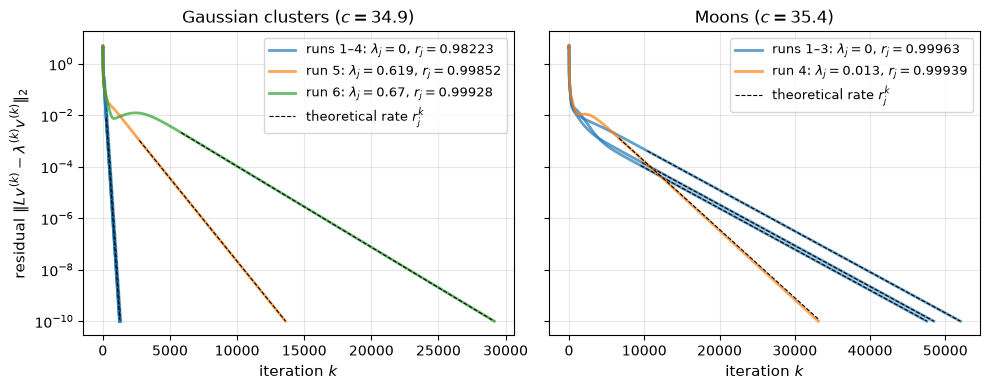

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
U_gauss, lams_gauss = deflation_convergence(L, lambdas, n_pairs=6, name="Gaussian clusters", ax=axes[0])
U_moons, lams_moons = deflation_convergence(L_moons, lambdas_moons, n_pairs=4, name="Moons", ax=axes[1], maxiter=100000)
axes[0].set_ylabel(r"residual $\|Lv^{(k)} - \lambda^{(k)} v^{(k)}\|_2$", fontsize=11)
fig.tight_layout()
fig.savefig("figures/power_conv.svg", bbox_inches="tight")
plt.show()

Every run converges linearly with exactly the theoretical rate $r_j$ (dashed lines), so the speed of power iteration is set by the gap between $\lambda_j$ and the next distinct eigenvalue, relative to $c$. For the Gaussian clusters, the runs for $\lambda = 0$ converge quickly because the gap to $\lambda_5$ is large, while runs 5 and 6 are much slower because $\lambda_5$, $\lambda_6$ and $\lambda_7$ lie close together. The bump at the start of run 6 is a transient before the asymptotic rate sets in. For the moons, the clusters are weakly connected, so $\lambda_4$ is close to $0$ and the runs for $\lambda = 0$ are much slower than for the Gaussian clusters. In all cases $r_j$ is close to $1$, since the gaps are small compared with $c \approx 35$.

In [20]:
# Effect of the shift c on convergence, first eigenpair of the Gaussian dataset
lam_max, lam_next = lambdas[-1], lambdas[4]           # largest eigenvalue, and next eigenvalue after 0
shifts = {"2 d_max (Gershgorin)": 2 * L.diagonal().max(),
          "lambda_max": lam_max,
          "(lambda_5 + lambda_max)/2 (optimal)": (lam_next + lam_max) / 2}

for name, c_test in shifts.items():
    r = max(abs(c_test - lam_next), abs(c_test - lam_max)) / c_test      # rate: second largest |eigenvalue| of cI - L over c
    lam, v, n_iter, conv, hist = power_iteration(L, maxiter=50000, seed=0, c=c_test)
    print(f"c = {c_test:6.2f} ({name}): r = {r:.4f}, iterations = {n_iter}, converged = {conv}")

c =  34.86 (2 d_max (Gershgorin)): r = 0.9822, iterations = 1231, converged = True
c =  19.03 (lambda_max): r = 0.9674, iterations = 667, converged = True
c =   9.82 ((lambda_5 + lambda_max)/2 (optimal)): r = 0.9369, iterations = 401, converged = True


A smaller shift gives a smaller rate and fewer iterations, in agreement with the theory: with the optimal shift the first eigenpair needs about a third of the iterations. However, the better shifts require $\lambda_{\max}$ and $\lambda_5$ in advance, and a shift below $\lambda_{\max}/2$ would make the method converge to the wrong eigenvalue, so we keep the safe Gershgorin bound $c = 2d_{\max}$.

The convergence plot shows how fast the method converges, but not whether it converges to the right eigenpairs. Next, we therefore compare the computed eigenpairs with the reference solution from `scipy.linalg.eigh`, and check that they give the same clustering as in Part 1.

In [21]:
# Deflated eigenpairs vs. the reference solution (scipy.linalg.eigh), Gaussian dataset
U, lams = U_gauss, lams_gauss
n_pairs = U.shape[1]
m = np.sum(np.abs(lambdas) < 1e-10 * lambdas[-1])            # multiplicity of lambda = 0

lam_err = np.abs(lams - lambdas[:n_pairs])                   # eigenvalue errors
orth = la.norm(U.T @ U - np.eye(n_pairs))                    # orthonormality of the computed vectors
res = la.norm(L @ U - U * lams, axis=0)                      # true residuals ||L u_j - lam_j u_j||, without deflation
dist = la.norm(V[:, :m] - U[:, :m] @ (U[:, :m].T @ V[:, :m]))  # distance between the eigenspaces of lambda = 0
overlap = np.abs(np.sum(U[:, m:] * V[:, m:n_pairs], axis=0)) # |u_j^T v_j| for the distinct eigenvalues
C_pi = KMeans(n_clusters=4, n_init=10, random_state=0).fit(U[:, :4]).labels_   # clustering with the computed vectors
C_pi_moons = KMeans(n_clusters=4, n_init=10, random_state=0).fit(U_moons).labels_ #clustering with the computed vectors for the moons dataset

print(f"max eigenvalue error = {lam_err.max():.1e}")
print(f"||U^T U - I|| = {orth:.1e}")
print(f"true residuals = {res}")
print(f"distance between eigenspaces of lambda = 0: {dist:.1e}")
print(f"overlaps |u_j^T v_j|, j = {m + 1}..{n_pairs}: {overlap}")
print(f"adjusted Rand index vs. Part 1 = {adjusted_rand_score(C_gauss, C_pi):.4f}")
print(f"adjusted Rand index vs. Part 1 (moons) = {adjusted_rand_score(C_moons, C_pi_moons):.4f}")

max eigenvalue error = 1.8e-14
||U^T U - I|| = 9.4e-16
true residuals = [9.96196137e-11 9.93019509e-11 9.96088889e-11 9.84530224e-11
 2.20605759e-10 1.43611207e-10]
distance between eigenspaces of lambda = 0: 3.2e-10
overlaps |u_j^T v_j|, j = 5..6: [1. 1.]
adjusted Rand index vs. Part 1 = 1.0000
adjusted Rand index vs. Part 1 (moons) = 1.0000


The computed eigenvalues are correct to rounding level, and deflation gives orthonormal vectors that span the correct eigenspace of $\lambda = 0$. The true residuals of $u_5, u_6$ are slightly above tol, since deflation inherits the errors of the earlier vectors. K-means on the computed eigenvectors gives exactly the same clustering as in Part 1, for both data sets (adjusted Rand index 1).

### Dependence on size and sparsity
Since the convergence rate depends on the eigengaps, we expect the performance to depend on the graph. We compute the four smallest eigenpairs for `make_data` while increasing the number of points $N$ (with $k = 10$), and while increasing the number of neighbours $k$ (with $N = 400$). We compare the total number of iterations with the prediction from $r_j$, and measure the time per iteration. Parameters: $c = 2d_{\max}$, tol $= 10^{-10}$, maxiter $= 50\,000$ per eigenpair, seed $j$ for run $j$, $\sigma = 1$; reference eigenvalues from `scipy.sparse.linalg.eigsh`.


In [22]:
def size_sparsity_run(L, n_pairs=4, tol=1e-10, maxiter=50000):
    '''
    Compute the n_pairs smallest eigenpairs of L with shifted power iteration and deflation, and return
    the quantities used to study the dependence on size and sparsity.

    Parameters:
        L: The graph Laplacian, scipy sparse matrix of shape (N,N)
        n_pairs: The number of eigenpairs to compute (default 4)
        tol: Tolerance for power iteration
        maxiter: The maximum number of iterations per run

    Return:
        dict with nnz(L), number of zero eigenvalues m, the next eigenvalue lambda_{n_pairs+1},
        total and predicted number of iterations, whether all runs converged, and time per iteration
    '''
    c = 2 * L.diagonal().max()
    ref = np.sort(eigsh(L, k=n_pairs + 6, sigma=-1e-3, which='LM', return_eigenvectors=False))  # reference eigenvalues (library)
    tol0 = 1e-8 * c                                                                             # threshold for "numerically equal"

    found, n_iters, preds, convs = [], [], [], []
    for j in range(n_pairs):
        lam, v, n_iter, conv, hist = power_iteration(L, tol=tol, maxiter=maxiter, seed=j, c=c, found=found)
        found.append(v); n_iters.append(n_iter); convs.append(conv)
        preds.append(np.log(tol / hist[0]) / np.log(theoretical_rate(ref, j, c, tol0)))  # k with ||res_0|| r_j^k = tol

    # Time per iteration: 500 iterations without early stop (tol = 0), best of 5 repeats
    times = []
    for _ in range(5):
        t0 = time.perf_counter()
        power_iteration(L, tol=0, maxiter=500, c=c, found=found[:-1])
        times.append(time.perf_counter() - t0)

    return dict(nnz=L.nnz, m=int(np.sum(ref < tol0)), lam_next=ref[n_pairs],
                iters=sum(n_iters), pred=sum(preds), conv=all(convs), t_iter=min(times) / 500)

In [23]:
# Size: N = 4n points from make_data, fixed k = 10
size_N, size_res = [], []
for n in [50, 100, 200, 400, 800, 1600]:
    np.random.seed(0)
    L_n = build_laplacian(make_data(n=n), k=10)
    size_N.append(4 * n)
    size_res.append(size_sparsity_run(L_n))

print("     N      nnz   m   lambda_5   iterations   predicted   converged   time/iter [us]")
for N, r in zip(size_N, size_res):
    print(f"{N:6d} {r['nnz']:8d} {r['m']:3d} {r['lam_next']:10.3g} {r['iters']:12d} {r['pred']:11.3g} "
          f"{str(r['conv']):>11} {1e6 * r['t_iter']:16.1f}")

     N      nnz   m   lambda_5   iterations   predicted   converged   time/iter [us]
   200     2778   4        1.1         2851    3.12e+03        True             12.0
   400     5446   4      0.619         5072    5.47e+03        True             15.3
   800    10656   4      0.345         9123    1.01e+04        True             20.5
  1600    20884   4       0.15        21314    2.43e+04        True             39.4
  3200    41224   2     0.0825       159431    3.26e+06       False             71.0
  6400    81266   3      0.044       167358    1.99e+06       False            123.6


As long as the four clusters are separate ($m = 4$), the number of iterations follows the prediction and grows with $N$. The degrees, and therefore $c$, stay almost constant, but each cluster becomes a larger graph, so $\lambda_5$ decreases and $r$ approaches $1$. For the largest $N$ the clusters start to touch ($m < 4$), some of the smallest eigenvalues become tiny and close together, and the runs reach maxiter. The time per iteration grows with $\operatorname{nnz}(L)$, which is proportional to $N$ here since the number of non-zeros per row is constant.

In [24]:
# Sparsity: fixed data set with N = 400 points, increasing number of neighbours k
np.random.seed(0)
X_s = make_data(n=100)
sparse_k, sparse_res = [], []
for k in [5, 10, 20, 40, 80, 160]:
    L_k = build_laplacian(X_s, k=k)
    sparse_k.append(k)
    sparse_res.append(size_sparsity_run(L_k))

print("    k      nnz  nnz/row   m   lambda_5   iterations   predicted   converged   time/iter [us]")
for k, r in zip(sparse_k, sparse_res):
    print(f"{k:5d} {r['nnz']:8d} {r['nnz'] / 400:8.1f} {r['m']:3d} {r['lam_next']:10.3g} {r['iters']:12d} "
          f"{r['pred']:11.3g} {str(r['conv']):>11} {1e6 * r['t_iter']:16.1f}")

    k      nnz  nnz/row   m   lambda_5   iterations   predicted   converged   time/iter [us]
    5     2922      7.3   4      0.122        13725    1.69e+04        True             12.9
   10     5446     13.6   4      0.619         5072    5.47e+03        True             14.2
   20    10588     26.5   4        2.2         2920    3.04e+03        True             17.7
   40    20544     51.4   4       11.2         1301    1.29e+03        True             24.0
   80    36856     92.1   3       23.8       150160    4.87e+05       False             37.7
  160    73648    184.1   1       25.1        68572    2.17e+05       False             70.2


Here the size is fixed, and the matrix becomes less sparse as $k$ increases. More neighbours make each cluster better connected, so $\lambda_5$ grows faster than $c$, $r$ decreases, and fewer iterations are needed, again in agreement with the prediction. For large $k$ the graph also connects the clusters ($m < 4$), and convergence becomes very slow again. The time per iteration grows with the number of non-zeros, as expected for a sparse matrix–vector product.

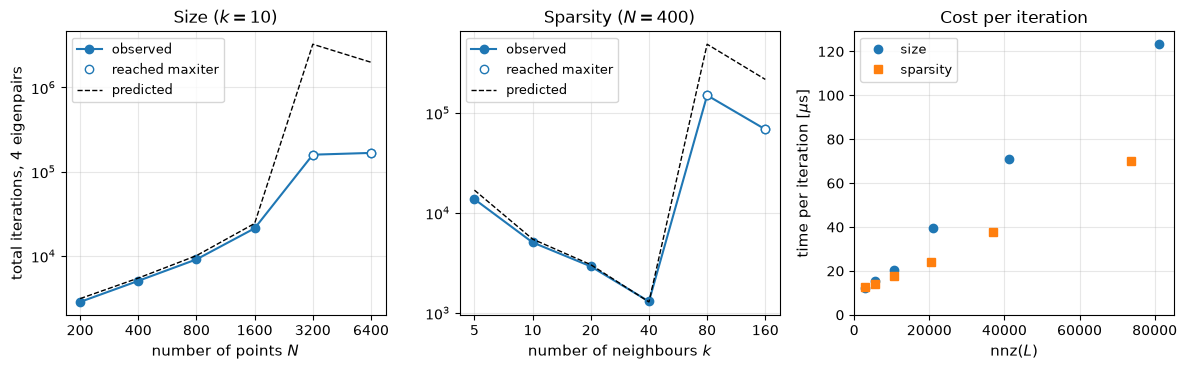

In [25]:
# Dependence on size and sparsity: iterations vs. N and k, and time per iteration vs. nnz(L)
fig, ax = plt.subplots(1, 3, figsize=(12, 3.8))

for a, x, res, xlabel, title in [(ax[0], size_N, size_res, "number of points $N$", "Size ($k = 10$)"),
                                 (ax[1], sparse_k, sparse_res, "number of neighbours $k$", "Sparsity ($N = 400$)")]:
    iters = [r["iters"] for r in res]
    a.loglog(x, iters, "o-", color="C0", label="observed")
    a.loglog([xi for xi, r in zip(x, res) if not r["conv"]], [r["iters"] for r in res if not r["conv"]],
             "o", color="C0", mfc="white", label="reached maxiter")             # hollow: not converged
    a.loglog(x, [r["pred"] for r in res], "k--", lw=1, label="predicted")
    a.set_xticks(x, x); a.minorticks_off()
    a.set_xlabel(xlabel, fontsize=11); a.set_title(title, fontsize=12)
    a.grid(alpha=0.3); a.legend(fontsize=9)
ax[0].set_ylabel("total iterations, 4 eigenpairs", fontsize=11)

ax[2].plot([r["nnz"] for r in size_res], [1e6 * r["t_iter"] for r in size_res], "o", label="size")
ax[2].plot([r["nnz"] for r in sparse_res], [1e6 * r["t_iter"] for r in sparse_res], "s", label="sparsity")
ax[2].set_xlim(left=0); ax[2].set_ylim(bottom=0)
ax[2].set_xlabel(r"$\mathrm{nnz}(L)$", fontsize=11); ax[2].set_ylabel(r"time per iteration [$\mu$s]", fontsize=11)
ax[2].set_title("Cost per iteration", fontsize=12)
ax[2].grid(alpha=0.3); ax[2].legend(fontsize=9)

fig.tight_layout()
fig.savefig("figures/power_size_sparsity.svg", bbox_inches="tight")
plt.show()

The number of iterations follows the predicted rates as long as the clusters are separate, so size and sparsity affect it only through the eigengaps. The time per iteration grows roughly linearly with $\operatorname{nnz}(L)$, so each iteration is cheap, but the total cost is set by the graph structure.

In [26]:
# Comparison with the library: our power iteration vs. scipy.sparse.linalg.eigsh, Gaussian dataset (N = 400)
t0 = time.perf_counter()
found = []
for j in range(4):
    lam, v, n_iter, conv, hist = power_iteration(L, maxiter=50000, seed=j, c=c, found=found)
    found.append(v)
t_power = time.perf_counter() - t0

t_eigsh = np.inf
for _ in range(5):                                     # best of 5, to exclude one-off start-up cost
    t0 = time.perf_counter()
    eigsh(L, k=4, sigma=-1e-3, which='LM')             # shift-invert Lanczos (library)
    t_eigsh = min(t_eigsh, time.perf_counter() - t0)

print(f"power iteration: {1e3 * t_power:.1f} ms,  eigsh: {1e3 * t_eigsh:.1f} ms")

power iteration: 76.7 ms,  eigsh: 2.7 ms


The library routine `eigsh` (shift-invert Lanczos) computes the same eigenpairs more than an order of magnitude faster, even for this small problem. In summary, shifted power iteration with deflation computes the eigenpairs needed for clustering correctly and cheaply per iteration, but its convergence is slow whenever the eigengaps are small compared with $c$, which motivates methods with better convergence.

## QR Iteration

## Lanczos Iteration